# SUNS – Zadanie č. 1

## Predikcia dokončenia nákupu v e-shope

Cieľom projektu je predpovedať, či návštevník e-shopu dokončí nákup
na základe údajov o svojej session a technických parametroch.

Cieľovou premennou je `Revenue`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "src" / "data_preparation.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Nije pronađen root direktorijum projekta.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

from IPython.display import Image, display

from src.data_preparation import load_data
from src.eda import (
    setup_plot_style,
    plot_purchase_rate_by_visitor_type,
)

setup_plot_style()

In [2]:
df_original = load_data()

df_clean = load_data(
    PROJECT_ROOT / "data" / "processed" / "online_shoppers_clean.csv"
)

print("Original:", df_original.shape)
print("Cleaned:", df_clean.shape)

display(df_clean.head())

Original: (12333, 19)
Cleaned: (12315, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2.0,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2.0,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10.0,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Unknown,True,False


## EDA 1 – Typ návštevníka a dokončenie nákupu

Analyzujeme, aký podiel sessions sa skončil nákupom v jednotlivých
kategóriách návštevníkov.

Porovnávame percentuálnu mieru nákupu, nie iba absolútny počet nákupov.
Pri každej kategórii uvádzame aj počet sessions.

Kategória `Unknown` označuje chýbajúce hodnoty typu návštevníka,
ktoré boli pri predspracovaní nahradené samostatnou kategóriou.

Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_purchase_rate_by_visitor_type.png


,VisitorType,sessions,purchases,purchase_rate
0,New_Visitor,1622,422,26.02
1,Other,82,16,19.51
2,Returning_Visitor,10118,1471,14.54
3,Admin,1,0,0.00
4,Unknown,492,0,0.00


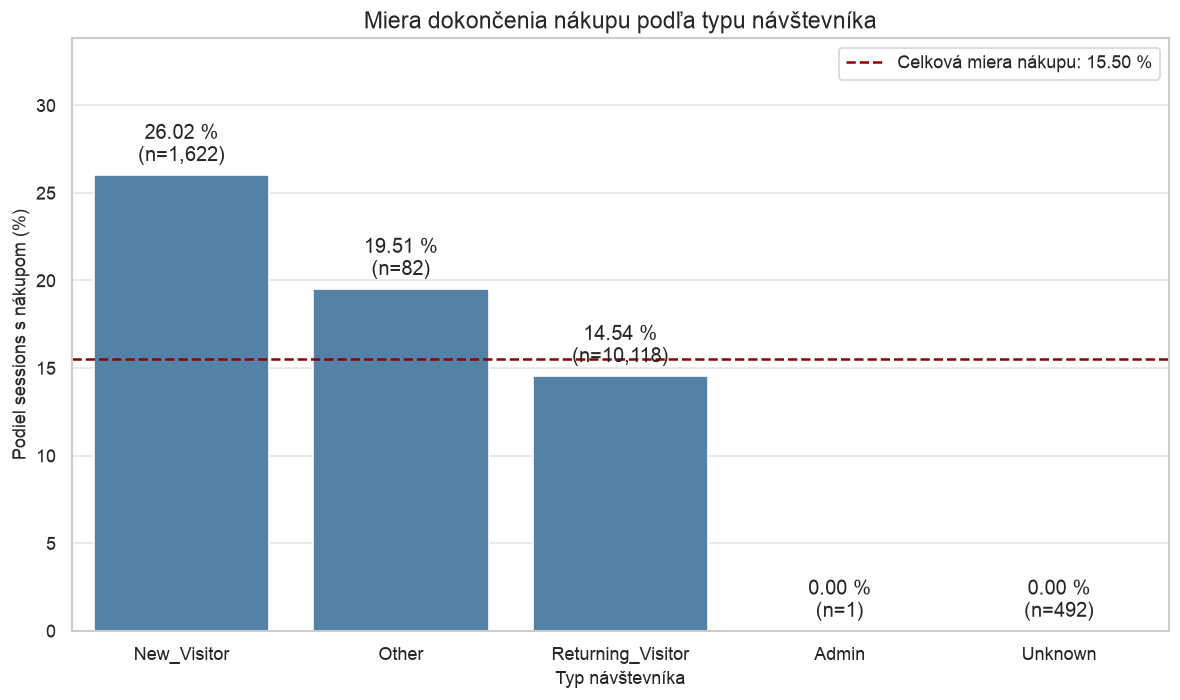

In [3]:
visitor_summary = plot_purchase_rate_by_visitor_type(df_clean)

display(visitor_summary.round(2))

display(
    Image(
        filename=str(
            PROJECT_ROOT
            / "results"
            / "figures"
            / "eda_purchase_rate_by_visitor_type.png"
        )
    )
)